# Stage 2: the baselines

**The question.** Before looking at what a video says or shows, how well can its lift be predicted from who made
it and when? `lift` is stage 1's target: the video's log share rate minus the median of its creator's last 30
videos posted at least 14 days earlier (notebook 01, cell 27). Four baselines, each simpler than any content model:

| | Baseline | Predicts lift as |
|---|---|---|
| B0 | Zero lift | 0: every video does as well as its creator's recent median |
| B1 | Recent form | the median of the creator's last 5 or 10 settled videos, or an exponentially weighted mean of them, minus the baseline |
| B2 | The creator's drift | the mean lift of the creator's earlier videos, shrunk toward 0 by n / (n + k) |
| B3 | Metadata | ridge and gradient-boosted trees on duration, posting hour and weekday, days since the previous video, the number of earlier videos, and wordless |

Every later stage has to beat the best of these. The code is in `src/sharerate` (the loader, the history features,
the metrics and the bootstrap), with its tests in `tests/`.

## 0. The bar, written before the first run (rule 7)

This cell was written, and committed, before any baseline was scored.

- **The label** is stage 1's as-of lift (`targets.lift`). Every history feature follows the same as-of rule: only
  videos posted strictly earlier, and for anything built from their share rates, only videos posted at least 14
  days earlier.
- **The rows** are the validation rows of `targets`, 21,332 videos from 203 creators, the same for every baseline.
  A baseline that needs more history than a row has predicts zero lift on that row, and the count is stated.
- **The primary bar.** A baseline beats zero lift if the 95% paired creator-bootstrap interval of its validation
  MAE gain (B0's MAE minus its own) lies above 0 for **seen** creators: 138 creators, 13,646 videos. New creators
  (27, 2,275 videos) and held-out creators (38, 5,411) are reported alongside and are not required to pass.
- **The secondary bar.** The gain in breakout ROC-AUC over B0's 0.5 has an interval above 0, and so does the gain
  in the top-10% share over B0's. B0's top-10% share is each creator's own breakout rate, close to the 0.242 base
  rate, so the paired gain compares a model with exactly what a random pick would get.
- **A miss is a miss.** A gain whose interval touches 0 is reported as "no better than the creator's recent
  median", never tuned until it passes. That result is publishable.
- **Every setting is chosen on validation,** by MAE over all 21,332 rows: B1's half-life, B2's k, the ridge
  penalty, the trees' size and number. The test split is never opened here; stage 5 opens it once.
- **Intervals** come from 2,000 replicates that resample creators, not videos, with every model and B0 scored on
  the same replicates.

## 1. The rows

**What.** Load the training and validation rows through `sharerate.data.load_videos`, and every library video's
post time for the timing features. Check the counts against stage 1's splits (`tests/test_data.py`).

**Why.** The loader is the only way into the data. It returns the target, the splits and two snapshot columns
(duration and wordless), and nothing measured after posting: a test in `tests/test_data.py` fails if a count,
`fetched_at`, `age_days` or a `files` column comes back. Usernames and video ids stay inside it; `creator` is an
opaque number.

**The mistake it avoids.** Opening the test split by accident: `load_videos()` returns train and validation only,
and the test rows come back only if asked for by name (stage 5).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sharerate import data, history
from sharerate.bootstrap import paired_creator_bootstrap
from sharerate.metrics import METRICS, eligible_creators

SEED, N_BOOT = 2026, 2_000  # one seed: every model and metric is scored on the same 2,000 creator draws
GROUPS = ["seen", "new", "holdout"]  # targets.creator_seen, rule 3's three ways
GROUP_NAMES = {"seen": "Seen creators", "new": "New creators (training group, no training rows)",
               "holdout": "Held-out creators"}
plt.rcParams.update({
    "figure.figsize": (8, 3.6),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

videos = data.load_videos()  # train and validation; the test split stays closed
posts = data.load_posting_times()  # when each target creator posted every library video
training = ((videos.time_split == "train") & (videos.creator_group == "train")).to_numpy()  # the only rows fitted on
validation = (videos.time_split == "validation").to_numpy()  # every setting is chosen here
val = videos[validation]

print(f"{len(videos):,} rows from {videos.creator.nunique()} creators, splits: {sorted(set(videos.time_split))}")
print(f"Columns: {', '.join(videos.columns)}")
print(f"Training: {training.sum():,} videos from {videos[training].creator.nunique()} creators")
print(f"Validation: {len(val):,} videos from {val.creator.nunique()} creators, "
      f"breakout rate {val.breakout.mean():.3f}, {val.has_twin.sum()} with a twin in training")
counts = val.groupby("creator_seen").agg(
    creators=("creator", "nunique"), videos=("lift", "size"), breakout_rate=("breakout", "mean"))
display(counts.loc[GROUPS].round(3))
# Stage 1's counts: if these move, the splits are not stage 1's.
assert (training.sum(), videos[training].creator.nunique()) == (74_552, 148)
assert counts.videos.to_dict() == {"holdout": 5_411, "new": 2_275, "seen": 13_646}

121,749 rows from 214 creators, splits: ['train', 'validation']
Columns: creator, published_at, time_split, creator_group, creator_seen, has_twin, n_prior, baseline, lift, breakout, duration_seconds, is_wordless
Training: 74,552 videos from 148 creators
Validation: 21,332 videos from 203 creators, breakout rate 0.242, 94 with a twin in training


,creators,videos,breakout_rate
creator_seen,,,
seen,138,13646,0.241
new,27,2275,0.265
holdout,38,5411,0.234


**What it says.** 121,749 training and validation rows from 214 creators; the test rows were not loaded. Models fit
on 74,552 videos from 148 creators. Validation holds 21,332 videos from 203 creators, with a breakout rate of
0.242: 13,646 from seen creators, 2,275 from new ones and 5,411 from held-out ones, stage 1's counts. New
creators break out a little more often (0.265 against 0.241).

## 2. What each video's history holds

**What.** For every row, count the creator's earlier target videos posted at least 14 days before it
(`history.settled_counts`). B1 and B2 are built from those videos' rates and lifts, so this is how much they
have to go on.

**Why.** History features follow the target's as-of rule: a rate is used only once its video is at least two
weeks old, when it had settled. The rates come from the target rows (log share rate = baseline + lift), so no
count is read. Target rows start only once a creator has ten settled videos, and everything after that is a
target, so whenever a row has at least 10 settled target videos, its last 5 and last 10 are exactly the
newest 5 and 10 videos of its own baseline.

**The mistake it avoids.** Recent form built from the videos just before this one. These creators post every
0.8 days, so the last few videos were still collecting shares when this one went up, and their rates were read
months later: a week in which the account got pushed would show up in the feature and in the label together.

In [2]:
n_settled = history.settled_counts(videos)
short = n_settled < history.MIN_HISTORY  # B1 has no prediction here and falls back to zero lift
coverage = pd.DataFrame({
    "videos": val.groupby("creator_seen").size(),
    "median settled earlier videos": pd.Series(n_settled[validation], index=val.index)
        .groupby(val.creator_seen).median(),
    f"fewer than {history.MIN_HISTORY} (B1 falls back to zero)": pd.Series(short[validation], index=val.index)
        .groupby(val.creator_seen).sum(),
}).loc[GROUPS]
display(coverage)
print(f"All validation: {short[validation].sum():,} of {validation.sum():,} rows "
      f"({short[validation].mean():.1%}) have fewer than {history.MIN_HISTORY} settled earlier target videos")

,videos,median settled earlier videos,fewer than 10 (B1 falls back to zero)
creator_seen,,,
seen,13646,521.0,82
new,2275,39.0,698
holdout,5411,836.0,163


All validation: 943 of 21,332 rows (4.4%) have fewer than 10 settled earlier target videos


**What it says.** Seen and held-out creators bring long histories into validation: a median of 521 and 836
settled earlier target videos. New creators bring a median of 39, and 698 of their 2,275 videos (31%) have fewer
than 10, so B1 predicts zero lift for those. Over all validation it is 943 rows (4.4%). Those rows score exactly
as B0 does, which pulls B1 toward B0 for new creators.

## 3. B0: zero lift

**What.** Predict `lift = 0` for every video: it will do as well as its creator's recent median. Score its MAE on
validation, overall and in each group.

**Why.** It is the bar every model must beat (section 0). Its error should match stage 1's: 0.371 overall (notebook 01), and
0.369 / 0.377 / 0.375 for seen, new and held-out creators.

**The mistake it avoids.** Comparing a model with a number from somewhere else. Every baseline below is scored on
exactly these rows, and its gain over B0 is computed inside each bootstrap replicate (section 8).

In [3]:
predictions = {"B0 zero lift": np.zeros(len(videos))}  # one prediction per row of `videos`; scored on validation


def validation_mae(pred):
    # The one number every setting below is chosen by: MAE over all 21,332 validation rows.
    return np.abs(val.lift.to_numpy() - pred[validation]).mean()


b0 = pd.Series({group: val.lift[val.creator_seen == group].abs().mean() for group in GROUPS})
print(f"B0 on all validation: MAE {validation_mae(predictions['B0 zero lift']):.4f} log10, "
      f"a factor of {10 ** validation_mae(predictions['B0 zero lift']):.2f} either way")
display(pd.DataFrame({"MAE": b0, "as a factor": 10 ** b0}).round(3))

B0 on all validation: MAE 0.3712 log10, a factor of 2.35 either way


,MAE,as a factor
seen,0.369,2.337
new,0.377,2.382
holdout,0.375,2.372


**What it says.** Zero lift misses by 0.371 log10 over all validation, a factor of 2.35 either way, and by 0.369,
0.377 and 0.375 for seen, new and held-out creators: stage 1's numbers. This is the bar.

## 4. B1: recent form

**What.** The median log share rate of the creator's last 5, and last 10, settled videos, minus the video's
baseline (`history.recent_form`). The baseline is the median of the last 30, so B1 asks whether the newest few
are running above or below it. The table also shows other window sizes and the lifetime, for the later slider.
Rows with fewer than 10 settled videos predict zero lift.

**Why.** If a creator is on a run, the next video may ride it. The 5 and 10 were fixed in advance,
not chosen here.

**The mistake it avoids.** Treating "no prediction" as a missing row. Every baseline is scored on the same
21,332 rows: where B1 has nothing to say it predicts what B0 predicts, and the count is stated (section 2).

In [4]:
def or_zero(pred):
    # Where a baseline has no prediction (too little history), it predicts zero lift, like B0.
    return np.nan_to_num(pred, nan=0.0)


windows = [5, 10, 20, 30, 50, 100, None]
recent = {window: history.recent_form(videos, window) for window in windows}
by_window = pd.DataFrame({
    "validation MAE": [validation_mae(or_zero(recent[w])) for w in windows],
    "mean prediction": [np.nanmean(recent[w][validation]) for w in windows],
}, index=pd.Index([str(w) if w else "lifetime" for w in windows], name="last N settled videos"))
display(by_window.round(4))
predictions["B1 median of last 5"] = or_zero(recent[5])
predictions["B1 median of last 10"] = or_zero(recent[10])

,validation MAE,mean prediction
last N settled videos,,
5,0.4058,0.0028
10,0.3867,0.0029
20,0.3752,0.0009
30,0.3713,-0.0001
50,0.3693,-0.0061
100,0.3699,-0.0135
lifetime,0.4265,-0.1378


**What it says.** Recent form, as a median of a few videos, makes the error worse. The last 5 settled videos miss
by 0.406 and the last 10 by 0.387, against 0.371 for zero lift. A median of five videos is itself noisy, and the
prediction carries all of that noise.

The other rows are for the later slider, not a choice: the 5 and 10 were fixed before the run, and
picking the best window now would be tuning on what the table shows. The last 30 is the baseline's own window,
so it scores like zero lift (0.3713). The lifetime median is by far the worst (0.4265), with a mean prediction of
−0.138: share rates drifted up (stage 1's 4.7×), so a lifetime yardstick under-predicts every new video. That is
stage 1's drift decision, measured again.

**What.** An exponentially weighted mean of the creator's settled log share rates, minus the baseline
(`history.ewm_form`). The newest settled video counts most; a video one half-life further back counts half as
much. The half-life, in videos, is chosen on validation from a grid fixed before looking.

**Why.** A median of 5 throws away everything older and weighs the five equally. A weighted mean uses all of
the history and lets the data say how fast the past should fade.

**The mistake it avoids.** Choosing the half-life on the rows the model is judged on and then calling the
result a test score. It is chosen on validation, as every setting is, and the honest score comes in stage 5,
from the test split this notebook never opens.

In [5]:
half_lives = [1, 2, 3, 5, 8, 13, 20, 30, 50, 100, 200]
ewm = {h: history.ewm_form(videos, h) for h in half_lives}
by_half_life = pd.Series({h: validation_mae(or_zero(ewm[h])) for h in half_lives},
                         name="validation MAE").rename_axis("half-life (videos)")
best_half_life = by_half_life.idxmin()
display(by_half_life.round(4).to_frame().T)
print(f"Chosen half-life: {best_half_life} videos (validation MAE {by_half_life.min():.4f}; "
      f"B0: {validation_mae(predictions['B0 zero lift']):.4f})")
predictions[f"B1 weighted mean, half-life {best_half_life}"] = or_zero(ewm[best_half_life])

half-life (videos),1,2,3,5,8,13,20,30,50,100,200
validation MAE,0.4137,0.3915,0.3833,0.3762,0.3722,0.37,0.3693,0.3698,0.3722,0.3792,0.3908


Chosen half-life: 20 videos (validation MAE 0.3693; B0: 0.3712)


**What it says.** The validation error falls as the half-life grows from 1 video (0.414) to 20 (0.3693), then
rises again (0.391 at 200). A half-life of 20 is chosen: a video 20 settled videos back counts half as much as the
newest. Its error, 0.3693, is 0.5% below zero lift's 0.3712, on the same rows that chose it. Section 8 says
whether that survives an interval.

## 5. B2: the creator's drift

**What.** The mean lift of the creator's settled earlier videos, times n / (n + k), where n is how many there
are (`history.shrunk_drift`). k is chosen on validation. k = 0 trusts the raw mean; k = infinity is B0.

**Why.** Lift compares a video with the creator's recent median. A creator who keeps growing beats their own
median most of the time, so their lift runs positive, and one who is fading runs negative. B2 asks whether that
persists. The shrinkage is there because a mean of a handful of videos is mostly luck: with n = 3 and k = 30,
the mean counts for 3/33 of itself; with n = 300, for 300/330.

**The mistake it avoids.** An extreme prediction for a creator with little history. Without shrinkage, three
lucky videos would predict a breakout for the fourth.

In [6]:
ks = [0, 1, 3, 10, 30, 100, 300, 1_000, 3_000, 10_000, np.inf]
drift = {k: history.shrunk_drift(videos, k) for k in ks}
by_k = pd.Series({k: validation_mae(drift[k]) for k in ks}, name="validation MAE").rename_axis("k")
best_k = by_k.idxmin()
display(by_k.round(4).to_frame().T)
print(f"Chosen k: {best_k} (validation MAE {by_k.min():.4f}; B0: {by_k[np.inf]:.4f})")

# A cross-check, not a choice: the k that empirical Bayes would pick from the training rows alone is the noise
# within a creator divided by the real spread of creators' mean lift (sigma^2 / tau^2).
per_creator = videos[training].groupby("creator").lift.agg(["mean", "var", "size"])
within = (per_creator["var"] * (per_creator["size"] - 1)).sum() / (per_creator["size"] - 1).sum()  # sigma^2
between = per_creator["mean"].var() - (within / per_creator["size"]).mean()  # tau^2: spread beyond the noise
print(f"On the training rows: within-creator variance {within:.4f}, between-creator variance {between:.5f}, "
      f"so empirical Bayes would pick k = {within / between:.0f}" if between > 0 else
      "On the training rows the creators' mean lifts spread no more than noise: empirical Bayes picks k = inf")
# k = infinity means no trust at all in the past mean: B2 is then B0, and the name says so.
predictions[f"B2 drift, k = {best_k:g}" + (" (= zero lift)" if np.isinf(best_k) else "")] = drift[best_k]

k,0.0,1.0,3.0,10.0,30.0,100.0,300.0,1000.0,3000.0,10000.0,inf
validation MAE,0.3793,0.3788,0.3783,0.3774,0.376,0.3742,0.3728,0.3718,0.3714,0.3712,0.3712


Chosen k: inf (validation MAE 0.3712; B0: 0.3712)
On the training rows: within-creator variance 0.2319, between-creator variance 0.00382, so empirical Bayes would pick k = 61


**What it says.** Every finite k does worse than zero lift, and the error falls steadily as k grows: 0.379 with no
shrinkage, 0.376 at k = 30, and 0.3712 at k = infinity. So the best B2 is no B2: B2 becomes B0, and is reported
under that name. A creator's past mean lift says nothing useful about their next video beyond what the baseline
already holds.

The cross-check agrees that there is little to find. On the training rows, creators' mean lifts spread by a
variance of 0.0038 against 0.232 within a creator, so empirical Bayes would trust a creator's mean halfway only
after 61 videos. On validation even that much trust costs accuracy (0.376 at k = 30, 0.374 at k = 100). The
rolling baseline already absorbs a creator's level and trend, and what is left in lift does not persist.

## 6. B3: metadata

**What.** Build the features B3 sees: log duration, wordless, how many earlier videos the library holds, days
since the previous one, the weekday, and the posting hour in two forms (`history.posting_features`):

- **the UTC hour,** as `published_at` records it;
- **the hour from the creator's usual hour,** from -12 to +12, where the usual hour is the circular mean of the
  creator's earlier posting hours (so 23:00 and 01:00 average to midnight, not noon).

**Why.** The creators live in different time zones, so the same UTC hour is evening for one and morning for
another. The raw hour mixes local times; the hour from the creator's own usual hour doesn't need to know the zone.
Earlier videos and days since the previous one count every library video, with or without counts.

**The mistake it avoids.** A timing feature that sees the future: every one of them uses only videos posted
strictly earlier, never the video itself or one posted in the same second (`tests/test_history.py`). "Wordless" was
labelled by a vision-language model (trap 5), and "earlier videos" counts my library, not the channel.

In [7]:
timing = history.posting_features(videos, posts)
features = pd.DataFrame({
    "log_duration": np.log10(videos.duration_seconds.clip(lower=1)),  # 10 videos have a duration of 0
    "wordless": videos.is_wordless,  # NaN for the videos the labelling pipeline never reached
    "log_earlier_videos": np.log10(1 + timing.earlier_videos),
    "log_days_since_previous": np.log10(1 + timing.days_since_previous),
    "weekday_utc": timing.weekday_utc,
    "hour_utc": timing.hour_utc,
    "hour_from_usual": timing.hour_from_usual,  # NaN until the creator has 10 earlier posts
})
# For the linear model the relative hour becomes 24 categories (rounded), with "unknown" as its own.
features["hour_from_usual_bin"] = (((features.hour_from_usual.round() + 12) % 24) - 12).fillna(-99).astype(int)

summary = pd.DataFrame({
    "training median": features[training].median(),
    "validation median": features[validation].median(),
    "missing in training": features[training].isna().sum(),
    "missing in validation": features[validation].isna().sum(),
}).drop(index="hour_from_usual_bin")
display(summary.round(2))
print(f"Validation videos posted within an hour of the creator's usual hour: "
      f"{(timing.hour_from_usual[validation].abs() <= 1).mean():.1%}")

,training median,validation median,missing in training,missing in validation
log_duration,1.11,1.08,0,0
wordless,0.00,0.00,44,71
log_earlier_videos,2.72,2.81,0,0
log_days_since_previous,0.29,0.21,0,0
weekday_utc,3.00,3.00,0,0
hour_utc,15.00,15.00,0,0
hour_from_usual,-0.05,0.65,0,0


Validation videos posted within an hour of the creator's usual hour: 19.9%


**What it says.** The median video runs about 13 s in training and 12 s in validation (log10 1.11 and 1.08). At
the median training video the creator has about 520 earlier library videos (log10 2.72), and the previous one went
up about 0.95 days before (0.62 in validation). Wordless is missing for 44 training and 71 validation videos,
which the labelling pipeline never reached. The hour from the usual hour is never missing on target rows, since
every target video has at least 10 earlier posts. Only 19.9% of validation videos went up within an hour of their
creator's usual hour, so the feature varies a lot, and its median moved from −0.05 hours in training to +0.65 in
validation.

**What.** Ridge regression of lift on the features, fitted on the training cell only, in three versions: no hour,
the UTC hour, and the hour from the usual hour (each as 24 categories). The penalty is chosen on validation.

**Why.** A linear model is the simplest way to ask whether metadata carries any signal at all. Comparing the three
versions on the same rows says which hour helps.

**The mistake it avoids.** Fitting on every training-period row. The held-out creators' training-period videos
only feed their baselines and are never fitted on (rule 3), so the model never sees a held-out creator.

In [8]:
NUMERIC = ["log_duration", "wordless", "log_earlier_videos", "log_days_since_previous"]
RIDGE_HOURS = {"no hour": [], "UTC hour": ["hour_utc"], "hour from usual": ["hour_from_usual_bin"]}
alphas = [0.1, 1, 10, 100, 1_000, 10_000]
y_train = videos.lift[training]


def ridge(alpha, numbers=NUMERIC, categories=("weekday_utc",)):
    steps = [
        # Fill a missing number with the training median and add a was-missing column, then standardise.
        ("numbers", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         list(numbers)),
    ]
    if categories:
        # One column per weekday (and per hour); a category unseen in training gets all zeros.
        steps.append(("categories", OneHotEncoder(handle_unknown="ignore"), list(categories)))
    return make_pipeline(ColumnTransformer(steps), Ridge(alpha=alpha))


ridge_mae = {}
for variant, hour_columns in RIDGE_HOURS.items():
    for alpha in alphas:
        model = ridge(alpha, categories=["weekday_utc"] + hour_columns).fit(features[training], y_train)
        ridge_mae[variant, alpha] = validation_mae(model.predict(features))
ridge_table = pd.Series(ridge_mae).unstack().rename_axis(index="hours", columns="alpha")
display(ridge_table.round(4))
for variant, hour_columns in RIDGE_HOURS.items():
    alpha = ridge_table.loc[variant].idxmin()
    model = ridge(alpha, categories=["weekday_utc"] + hour_columns).fit(features[training], y_train)
    predictions[f"B3 ridge, {variant}"] = model.predict(features)
    print(f"B3 ridge, {variant}: alpha {alpha:g}, validation MAE {ridge_table.loc[variant].min():.4f}")

alpha,0.1,1.0,10.0,100.0,1000.0,10000.0
hours,,,,,,
UTC hour,0.3707,0.3707,0.3707,0.3707,0.3706,0.3707
hour from usual,0.3707,0.3707,0.3707,0.3707,0.3707,0.3707
no hour,0.3706,0.3706,0.3706,0.3706,0.3706,0.3707


B3 ridge, no hour: alpha 0.1, validation MAE 0.3706


B3 ridge, UTC hour: alpha 1000, validation MAE 0.3706


B3 ridge, hour from usual: alpha 1000, validation MAE 0.3707


**What it says.** The penalty barely matters: every alpha gives 0.3706 to 0.3707 in every version, against 0.3712
for zero lift. With 74,552 training rows and at most 36 columns there is little to shrink. The three hour versions
are within 0.0001 of each other.

**What.** What B3 ridge learned. First its coefficients (the no-hour version, each per standard deviation of its
feature, in log10 units of lift). Then the same model refitted with one feature left out at a time, and how much
the validation error grows without it, with the paired creator bootstrap (the full model as the base).

**Why.** The metadata models' gains are a fraction of a percent, and a gain that small could come from any
column. Leaving one out at a time shows which one carries it.

**The mistake it avoids.** Telling a story about posting habits when the whole gain comes from a single column.

In [9]:
ridge_alpha = ridge_table.loc["no hour"].idxmin()
fitted = ridge(ridge_alpha).fit(features[training], y_train)
coefficients = pd.Series(fitted[-1].coef_, index=fitted[0].get_feature_names_out(), name="per standard deviation")
display(coefficients.round(4).to_frame())
per_doubling = coefficients["numbers__log_duration"] / features.loc[training, "log_duration"].std() * np.log10(2)
print(f"Duration: {per_doubling:+.4f} log10 of lift per doubling of the length "
      f"(a factor of {10 ** per_doubling:.3f})")

left_out = {"all features": predictions["B3 ridge, no hour"]}
for column in NUMERIC + ["weekday_utc"]:
    model = ridge(ridge_alpha, numbers=[c for c in NUMERIC if c != column],
                  categories=[] if column == "weekday_utc" else ["weekday_utc"])
    left_out[f"without {column}"] = model.fit(features[training], y_train).predict(features)
ablation = {}
for group in GROUPS:
    rows = validation & (videos.creator_seen == group).to_numpy()
    table = paired_creator_bootstrap(
        METRICS["MAE"][0], videos.lift.to_numpy()[rows], {name: pred[rows] for name, pred in left_out.items()},
        videos.creator.to_numpy()[rows], base="all features", lower_is_better=True, n_boot=N_BOOT, seed=SEED)
    # gain < 0 means the error grew without the column; shown as how much it grew
    ablation[group] = [f"{-r.gain:+.4f} [{-r.gain_high:+.4f}, {-r.gain_low:+.4f}]"
                       for r in table.drop(index="all features").itertuples()]
display(pd.DataFrame(ablation, index=[name for name in left_out if name != "all features"])
        .rename_axis("validation MAE grows by"))

,per standard deviation
numbers__log_duration,-0.0161
numbers__wordless,-0.0070
numbers__log_earlier_videos,-0.0005
numbers__log_days_since_previous,0.0176
numbers__missingindicator_wordless,-0.0028
categories__weekday_utc_0,0.0051
categories__weekday_utc_1,0.0013
categories__weekday_utc_2,-0.0010
categories__weekday_utc_3,-0.0006
categories__weekday_utc_4,-0.0039


Duration: -0.0157 log10 of lift per doubling of the length (a factor of 0.964)


,seen,new,holdout
validation MAE grows by,,,
without log_duration,"+0.0007 [+0.0004, +0.0011]","-0.0002 [-0.0022, +0.0013]","+0.0010 [+0.0001, +0.0018]"
without wordless,"+0.0001 [-0.0000, +0.0002]","+0.0002 [-0.0002, +0.0004]","-0.0001 [-0.0004, +0.0002]"
without log_earlier_videos,"+0.0000 [-0.0000, +0.0000]","+0.0001 [+0.0000, +0.0001]","-0.0000 [-0.0000, +0.0000]"
without log_days_since_previous,"+0.0000 [-0.0003, +0.0004]","-0.0009 [-0.0024, +0.0001]","+0.0004 [-0.0001, +0.0008]"
without weekday_utc,"+0.0001 [-0.0000, +0.0001]","+0.0000 [-0.0001, +0.0001]","+0.0000 [-0.0001, +0.0001]"


**What it says.** Duration carries B3. Leave it out and the seen creators' error grows by 0.0007 [0.0004, 0.0011],
the model's whole gain over zero lift, and the held-out creators' by 0.0010 [0.0001, 0.0018]. Every other column's
interval includes 0 for seen and held-out creators. Shorter videos beat their creator's median slightly more often:
each doubling of the length lowers the predicted lift by 0.016 log10, a factor of 0.964, so a 60-second video
(two doublings of 15 s) is predicted to do about 7% worse against its creator's median than a 15-second one. The
days since the previous video has the largest coefficient (+0.018 per standard deviation), but leaving it out costs
nothing on validation: what it learned in training does not carry over.

**What.** Gradient-boosted trees (scikit-learn's `HistGradientBoostingRegressor`) on the same features, in the
same three versions. The hour goes in as a number: trees can cut it anywhere. The tree size and the number of
trees are chosen on validation, reading the validation error after every tree.

**Why.** Trees find what ridge can't: a duration that helps only up to a point, an hour that matters only on some
days. If metadata has a signal that isn't a straight line, this is where it shows.

**The mistake it avoids.** Overfitting creators. Each leaf needs at least 200 training videos, so no leaf can be
one creator's quirk learned by heart, and boosting stops at the number of trees that does best on validation.

In [10]:
TREE_HOURS = {"no hour": [], "UTC hour": ["hour_utc"], "hour from usual": ["hour_from_usual"]}
TREE_NUMERIC = NUMERIC + ["weekday_utc"]
leaf_counts, max_trees = [7, 15, 31], 400


def trees(leaves, n_trees):
    # Deterministic: no early stopping and no subsampling, so the same settings give the same model.
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=n_trees, max_leaf_nodes=leaves,
                                         min_samples_leaf=200, early_stopping=False, random_state=0)


tree_choice = {}
for variant, hour_columns in TREE_HOURS.items():
    columns = TREE_NUMERIC + hour_columns
    for leaves in leaf_counts:
        model = trees(leaves, max_trees).fit(features.loc[training, columns], y_train)
        # The validation error after 1, 2, ..., 400 trees, read in one pass.
        curve = [np.abs(val.lift.to_numpy() - stage).mean()
                 for stage in model.staged_predict(features.loc[validation, columns])]
        tree_choice[variant, leaves] = (min(curve), int(np.argmin(curve)) + 1)
tree_table = pd.DataFrame(tree_choice, index=["validation MAE", "trees"]).T.rename_axis(["hours", "leaves"])
display(tree_table.round(4))
for variant, hour_columns in TREE_HOURS.items():
    columns = TREE_NUMERIC + hour_columns
    leaves = tree_table.loc[variant, "validation MAE"].idxmin()
    n_trees = int(tree_table.loc[(variant, leaves), "trees"])
    model = trees(leaves, n_trees).fit(features.loc[training, columns], y_train)
    predictions[f"B3 trees, {variant}"] = model.predict(features[columns])
    print(f"B3 trees, {variant}: {leaves} leaves, {n_trees} trees, "
          f"validation MAE {validation_mae(predictions[f'B3 trees, {variant}']):.4f}")

validation MAE  trees
hours           leaves                       
no hour         7               0.3704   83.0
                15              0.3706   50.0
                31              0.3708   18.0
UTC hour        7               0.3704   85.0
                15              0.3705   49.0
                31              0.3707   18.0
hour from usual 7               0.3705   66.0
                15              0.3706   27.0
                31              0.3707   16.0

B3 trees, no hour: 7 leaves, 83 trees, validation MAE 0.3704


B3 trees, UTC hour: 7 leaves, 85 trees, validation MAE 0.3704


B3 trees, hour from usual: 7 leaves, 66 trees, validation MAE 0.3705


**What it says.** Small trees win: 7 leaves and 66 to 85 trees in each version, with a validation error of 0.3704
to 0.3705, a hair below ridge's 0.3706. Bigger trees stop improving after 16 to 50 trees and end worse. There is no
curved signal here that ridge missed.

## 7. A leak, for reference: `has_video`

**What.** Whether the clip's video file still exists, used the way a model would use it: the training rows' mean
lift for kept clips and for retired ones, predicted for each validation video. It comes from
`data.load_leak_reference`, a separate function, because the loader refuses every `files` column.

**Why.** To show what a leak looks like next to honest baselines. The platform keeps each channel's top clips by
share rate, so a clip that still has its file was a winner (trap 3). This number is not a model, can't exist
before posting, and is never a feature.

**The mistake it avoids.** Reading a big gain as a good model. When something beats every honest baseline by far,
the first question is whether it could have known the answer.

In [11]:
kept = data.load_leak_reference().to_numpy()  # 1 if the clip's file still exists today
leak_means = pd.Series(videos.lift.to_numpy()[training]).groupby(kept[training]).mean()
predictions["has_video (a LEAK, not a model)"] = leak_means.reindex(kept).to_numpy()
print(f"Training mean lift: kept clips {leak_means[1]:+.3f}, retired clips {leak_means[0]:+.3f}; "
      f"kept share of validation videos {kept[validation].mean():.1%}")

Training mean lift: kept clips +0.175, retired clips -0.071; kept share of validation videos 38.8%


**What it says.** In training, clips that still have their file beat their creator's median by +0.175 log10 on
average, and retired ones fall short by 0.071. 38.8% of validation videos are kept clips. A model given this column
would look good for a reason that cannot exist before posting.

## 8. Every baseline, every metric, three ways

**What.** Score each prediction on the validation rows of each creator group with every metric in `sharerate.metrics`, and its
gain over B0 with a 95% paired creator-bootstrap interval (`sharerate.bootstrap.paired_creator_bootstrap`, 2,000
replicates). The metrics:

- on lift: **MAE** (log10; 10^MAE is the factor), the **skill score** 1 − Σ(lift − prediction)² / Σ lift² (zero
  lift scores 0; this is not the R² of log share rate), and **Spearman inside each creator**, averaged over
  creators with at least 20 validation videos, each creator weighing the same;
- on breakout (lift ≥ log10 2), with the predicted lift as the score: **ROC-AUC**, **PR-AUC** (against the base
  rate), and the **top-10% share**, the share of breakouts among each creator's top tenth by prediction, averaged
  over the same creators.

Each cell reads "the baseline's value, then its gain over B0 [95% interval]". A positive gain means better, for
MAE too (B0's error minus the baseline's).

**Why.** One creator's videos are alike, so creators, not videos, are the independent units: each replicate
draws creators with replacement and keeps all their videos. The gain is taken inside each replicate, so a draw
of easy creators flatters every model alike and cancels out.

**The mistake it avoids.** Intervals that are far too narrow (resampling videos), and two separate intervals that
overlap even when one model beats the other on every draw.

In [12]:
results = []
for group in GROUPS:
    rows = validation & (videos.creator_seen == group).to_numpy()
    for metric_name, (metric, lower_is_better) in METRICS.items():
        table = paired_creator_bootstrap(
            metric, videos.lift.to_numpy()[rows], {name: pred[rows] for name, pred in predictions.items()},
            videos.creator.to_numpy()[rows], base="B0 zero lift", lower_is_better=lower_is_better,
            n_boot=N_BOOT, seed=SEED)
        results.append(table.assign(group=group, metric=metric_name).rename_axis("model").reset_index())
results = pd.concat(results, ignore_index=True)

DIGITS = {"MAE": 4, "skill": 4}  # the lift errors move in the fourth decimal; the rest show three


def cell(row):
    digits = DIGITS.get(row.metric, 3)
    return (f"{row.value:.{digits}f}  {row.gain:+.{digits}f} "
            f"[{row.gain_low:+.{digits}f}, {row.gain_high:+.{digits}f}]")


for group in GROUPS:
    part = results[results.group == group]
    rows = validation & (videos.creator_seen == group).to_numpy()
    codes = pd.factorize(videos.creator.to_numpy()[rows])[0]
    b0_mae = part[(part.model == "B0 zero lift") & (part.metric == "MAE")].iloc[0]
    print(f"\n{GROUP_NAMES[group]}: {rows.sum():,} videos from {codes.max() + 1} creators "
          f"({eligible_creators(codes)} with at least 20, for the within-creator metrics). "
          f"B0's MAE: {b0_mae.value:.3f} [{b0_mae.value_low:.3f}, {b0_mae.value_high:.3f}]")
    display(part.assign(text=part.apply(cell, axis=1))
            .pivot(index="model", columns="metric", values="text")
            .loc[list(predictions), list(METRICS)])


Seen creators: 13,646 videos from 138 creators (103 with at least 20, for the within-creator metrics). B0's MAE: 0.369 [0.341, 0.397]


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3687 -0.0000 [-0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.241 +0.000 [+0.000, +0.000]","0.247 +0.000 [+0.000, +0.000]"
B1 median of last 5,"0.4033 -0.0346 [-0.0399, -0.0298]","-0.1840 -0.1840 [-0.2128, -0.1544]","0.007 +0.007 [-0.022, +0.036]","0.522 +0.022 [+0.007, +0.037]","0.267 +0.026 [+0.013, +0.040]","0.244 -0.003 [-0.034, +0.029]"
B1 median of last 10,"0.3835 -0.0148 [-0.0186, -0.0117]","-0.0742 -0.0742 [-0.0921, -0.0586]","0.002 +0.002 [-0.026, +0.029]","0.524 +0.024 [+0.007, +0.039]","0.264 +0.023 [+0.010, +0.034]","0.229 -0.018 [-0.047, +0.013]"
"B1 weighted mean, half-life 20","0.3662 +0.0025 [-0.0005, +0.0053]","0.0336 +0.0336 [+0.0218, +0.0485]","0.146 +0.146 [+0.111, +0.180]","0.588 +0.088 [+0.070, +0.105]","0.311 +0.070 [+0.056, +0.086]","0.320 +0.073 [+0.042, +0.104]"
"B2 drift, k = inf (= zero lift)","0.3687 -0.0000 [-0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.241 +0.000 [+0.000, +0.000]","0.247 +0.000 [+0.000, +0.000]"
"B3 ridge, no hour","0.3681 +0.0007 [+0.0002, +0.0011]","0.0039 +0.0039 [+0.0017, +0.0064]","0.071 +0.071 [+0.043, +0.101]","0.536 +0.036 [+0.010, +0.063]","0.263 +0.022 [+0.008, +0.038]","0.290 +0.043 [+0.011, +0.078]"
"B3 ridge, UTC hour","0.3681 +0.0006 [+0.0002, +0.0011]","0.0038 +0.0038 [+0.0014, +0.0063]","0.064 +0.064 [+0.034, +0.095]","0.538 +0.038 [+0.011, +0.063]","0.264 +0.023 [+0.009, +0.038]","0.296 +0.049 [+0.014, +0.082]"
"B3 ridge, hour from usual","0.3681 +0.0006 [+0.0001, +0.0011]","0.0035 +0.0035 [+0.0012, +0.0061]","0.070 +0.070 [+0.042, +0.100]","0.532 +0.032 [+0.004, +0.062]","0.260 +0.019 [+0.004, +0.037]","0.287 +0.040 [+0.004, +0.078]"
"B3 trees, no hour","0.3681 +0.0006 [-0.0001, +0.0014]","0.0050 +0.0050 [+0.0004, +0.0105]","0.063 +0.063 [+0.035, +0.093]","0.527 +0.027 [+0.001, +0.054]","0.257 +0.016 [+0.001, +0.034]","0.297 +0.050 [+0.022, +0.076]"



New creators (training group, no training rows): 2,275 videos from 27 creators (20 with at least 20, for the within-creator metrics). B0's MAE: 0.377 [0.331, 0.433]


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3770 -0.0000 [-0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.265 +0.000 [+0.000, +0.000]","0.289 +0.000 [+0.000, +0.000]"
B1 median of last 5,"0.4035 -0.0266 [-0.0411, -0.0110]","-0.1148 -0.1148 [-0.2104, -0.0461]","0.029 +0.029 [-0.033, +0.091]","0.520 +0.020 [-0.013, +0.064]","0.284 +0.018 [-0.001, +0.065]","0.339 +0.050 [-0.030, +0.137]"
B1 median of last 10,"0.3936 -0.0166 [-0.0356, +0.0034]","-0.0502 -0.0502 [-0.1616, +0.0342]","0.032 +0.032 [-0.053, +0.125]","0.505 +0.005 [-0.030, +0.050]","0.270 +0.005 [-0.015, +0.064]","0.276 -0.012 [-0.087, +0.070]"
"B1 weighted mean, half-life 20","0.3750 +0.0019 [-0.0058, +0.0073]","0.0152 +0.0152 [-0.0185, +0.0396]","0.103 +0.103 [+0.037, +0.162]","0.580 +0.080 [+0.034, +0.110]","0.306 +0.040 [+0.011, +0.067]","0.355 +0.066 [-0.004, +0.138]"
"B2 drift, k = inf (= zero lift)","0.3770 -0.0000 [-0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.265 +0.000 [+0.000, +0.000]","0.289 +0.000 [+0.000, +0.000]"
"B3 ridge, no hour","0.3774 -0.0004 [-0.0030, +0.0009]","-0.0032 -0.0032 [-0.0153, +0.0054]","-0.013 -0.013 [-0.103, +0.073]","0.505 +0.005 [-0.071, +0.053]","0.265 -0.000 [-0.033, +0.030]","0.299 +0.010 [-0.074, +0.100]"
"B3 ridge, UTC hour","0.3773 -0.0003 [-0.0028, +0.0010]","-0.0026 -0.0026 [-0.0143, +0.0054]","0.011 +0.011 [-0.082, +0.099]","0.508 +0.008 [-0.066, +0.060]","0.268 +0.003 [-0.030, +0.033]","0.313 +0.024 [-0.061, +0.117]"
"B3 ridge, hour from usual","0.3775 -0.0006 [-0.0036, +0.0010]","-0.0045 -0.0045 [-0.0180, +0.0043]","0.004 +0.004 [-0.082, +0.092]","0.490 -0.010 [-0.078, +0.031]","0.258 -0.008 [-0.037, +0.018]","0.258 -0.030 [-0.104, +0.048]"
"B3 trees, no hour","0.3754 +0.0016 [+0.0007, +0.0024]","0.0061 +0.0061 [-0.0016, +0.0122]","0.012 +0.012 [-0.071, +0.084]","0.565 +0.065 [+0.006, +0.102]","0.307 +0.042 [+0.006, +0.074]","0.253 -0.036 [-0.123, +0.049]"



Held-out creators: 5,411 videos from 38 creators (33 with at least 20, for the within-creator metrics). B0's MAE: 0.375 [0.336, 0.418]


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3752 -0.0000 [-0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.234 +0.000 [+0.000, +0.000]","0.228 +0.000 [+0.000, +0.000]"
B1 median of last 5,"0.4130 -0.0378 [-0.0483, -0.0277]","-0.1842 -0.1842 [-0.2453, -0.1229]","0.026 +0.026 [-0.024, +0.082]","0.526 +0.026 [+0.002, +0.054]","0.267 +0.033 [+0.014, +0.056]","0.278 +0.050 [+0.003, +0.099]"
B1 median of last 10,"0.3920 -0.0168 [-0.0224, -0.0099]","-0.0785 -0.0785 [-0.1148, -0.0421]","0.026 +0.026 [-0.027, +0.078]","0.519 +0.019 [-0.010, +0.062]","0.267 +0.034 [+0.011, +0.070]","0.303 +0.074 [+0.019, +0.135]"
"B1 weighted mean, half-life 20","0.3747 +0.0005 [-0.0101, +0.0077]","0.0512 +0.0512 [+0.0232, +0.0733]","0.089 +0.089 [+0.023, +0.152]","0.631 +0.131 [+0.087, +0.167]","0.361 +0.128 [+0.078, +0.184]","0.339 +0.111 [+0.043, +0.184]"
"B2 drift, k = inf (= zero lift)","0.3752 -0.0000 [-0.0000, +0.0000]","0.0000 +0.0000 [+0.0000, +0.0000]","0.000 +0.000 [+0.000, +0.000]","0.500 +0.000 [+0.000, +0.000]","0.234 +0.000 [+0.000, +0.000]","0.228 +0.000 [+0.000, +0.000]"
"B3 ridge, no hour","0.3743 +0.0009 [-0.0000, +0.0017]","0.0054 +0.0054 [-0.0004, +0.0101]","0.083 +0.083 [+0.018, +0.147]","0.525 +0.025 [-0.005, +0.059]","0.250 +0.017 [+0.000, +0.043]","0.247 +0.019 [-0.034, +0.071]"
"B3 ridge, UTC hour","0.3743 +0.0009 [-0.0001, +0.0017]","0.0050 +0.0050 [-0.0007, +0.0097]","0.076 +0.076 [+0.015, +0.140]","0.527 +0.027 [-0.004, +0.062]","0.254 +0.020 [+0.004, +0.046]","0.258 +0.029 [-0.021, +0.079]"
"B3 ridge, hour from usual","0.3741 +0.0011 [+0.0001, +0.0019]","0.0059 +0.0059 [-0.0001, +0.0107]","0.105 +0.105 [+0.048, +0.163]","0.523 +0.023 [-0.005, +0.054]","0.248 +0.014 [-0.001, +0.039]","0.257 +0.029 [-0.015, +0.078]"
"B3 trees, no hour","0.3739 +0.0013 [-0.0006, +0.0031]","0.0041 +0.0041 [-0.0042, +0.0120]","0.066 +0.066 [+0.010, +0.120]","0.495 -0.005 [-0.039, +0.031]","0.232 -0.002 [-0.015, +0.020]","0.239 +0.011 [-0.032, +0.053]"


**What it says.** For seen creators:

- **B3 ridge** is the only baseline whose MAE gain clears 0: +0.0007 [+0.0002, +0.0011] in the no-hour version, an
  error 0.2% smaller. It also ranks: ROC-AUC 0.536, and of each creator's top tenth by its prediction, 29.0% broke
  out against 24.7% for B0.
- **B1, the weighted mean,** has the largest point gain, +0.0025, but its interval [−0.0005, +0.0053] touches 0. It
  is the best ranker of any honest baseline by a wide margin: skill +0.034 [+0.022, +0.049], Spearman inside a
  creator 0.146 [0.111, 0.180] over 103 creators, ROC-AUC 0.588, PR-AUC 0.311 against 0.241, and a top-10% share of
  0.320 against 0.247. It gets the big moves right more than the typical video: the skill score squares errors and
  rewards that, the MAE counts the typical error and does not.
- **B1's medians** are worse than zero lift on MAE and skill in every group, with ROC-AUCs just above 0.5.
- **B3 trees** gain about as much as ridge (+0.0006) with a wider interval that touches 0.

For new creators, only the trees clear 0 on MAE (+0.0016 [+0.0007, +0.0024] without an hour). For held-out
creators, only ridge with the hour from the usual hour does (+0.0011 [+0.0001, +0.0019]). The leak beats every
honest baseline in every group: +0.019 [+0.011, +0.028] for seen creators, ROC-AUC 0.693, and a top-10% share of
0.633.

## 9. The chart: each baseline's gain over zero lift

**What.** Each baseline's validation MAE gain over B0, with its 95% paired interval, for the three creator
groups side by side. A filled dot is a gain whose interval lies above 0; a hollow one touches or crosses 0.

**Why.** It is the bar in one picture: a dot whose whisker stays right of the line beats "every video does as
well as its creator's recent median" for that group.

**The mistake it avoids.** Showing a point without its interval, which makes every gain look real. The leak is
drawn in grey and labelled, so nobody reads it as a model.

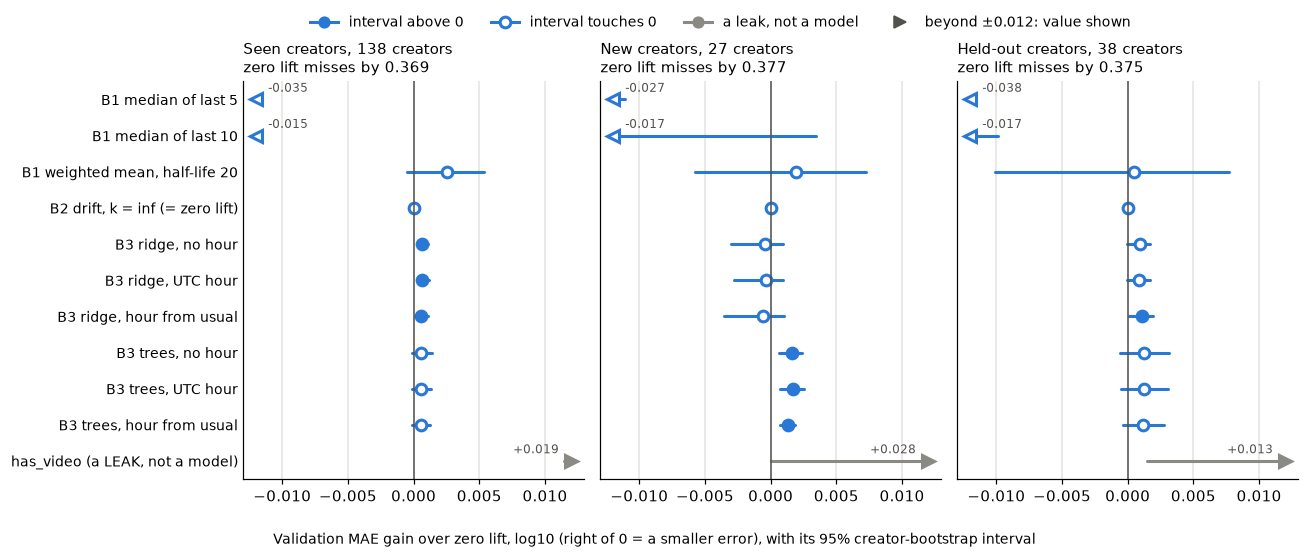

In [13]:
BLUE, GREY, MUTED, GRID = "#2a78d6", "#8a8984", "#52514e", "#e4e3df"
LIMIT = 0.012  # the scale of the gains that matter; anything beyond is drawn at the edge, with its value
order = [name for name in predictions if name != "B0 zero lift"]
gains = results[results.metric == "MAE"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8), sharey=True, sharex=True)
for ax, group in zip(axes, GROUPS):
    part = gains[gains.group == group].set_index("model")
    for y, name in enumerate(reversed(order)):
        r = part.loc[name]
        colour = GREY if "LEAK" in name else BLUE
        clears = r.gain_low > 0  # filled when the interval lies above 0
        low, high = np.clip([r.gain_low, r.gain_high], -LIMIT, LIMIT)
        if low < high:  # nothing to draw when the whole interval is off the scale
            ax.plot([low, high], [y, y], color=colour, linewidth=2, solid_capstyle="round")
        if abs(r.gain) <= LIMIT:
            ax.plot(r.gain, y, "o", markersize=7, markeredgewidth=2, color=colour,
                    markerfacecolor=colour if clears else "white")
        else:  # off the scale: an arrowhead at the edge, and the value beside it
            edge = np.sign(r.gain) * LIMIT
            ax.plot(edge, y, ">" if r.gain > 0 else "<", markersize=8, markeredgewidth=2, color=colour,
                    markerfacecolor=colour if clears else "white")
            ax.annotate(f"{r.gain:+.3f}", (edge, y), xytext=(-8 if r.gain > 0 else 8, 5),
                        textcoords="offset points", ha="right" if r.gain > 0 else "left", fontsize=8,
                        color=MUTED)
    ax.set_xlim(-LIMIT * 1.08, LIMIT * 1.08)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    n_creators = val[val.creator_seen == group].creator.nunique()
    ax.set_title(f"{GROUP_NAMES[group].split(' (')[0]}, {n_creators} creators\n"
                 f"zero lift misses by {part.loc['B0 zero lift', 'value']:.3f}", loc="left", fontsize=10)
axes[0].set_yticks(range(len(order)), list(reversed(order)), fontsize=9)
fig.supxlabel("Validation MAE gain over zero lift, log10 (right of 0 = a smaller error), with its 95% "
              "creator-bootstrap interval", fontsize=9)
fig.legend(handles=[
    plt.Line2D([], [], marker="o", color=BLUE, markersize=7, linewidth=2, label="interval above 0"),
    plt.Line2D([], [], marker="o", color=BLUE, markerfacecolor="white", markersize=7, markeredgewidth=2,
               linewidth=2, label="interval touches 0"),
    plt.Line2D([], [], marker="o", color=GREY, markersize=7, linewidth=2, label="a leak, not a model"),
    plt.Line2D([], [], marker=">", color=MUTED, markersize=8, linestyle="none",
               label=f"beyond ±{LIMIT}: value shown"),
], loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.55, 1.04), fontsize=9)
fig.tight_layout()
plt.show()

**What it says.** Apart from B1's two medians, every honest baseline sits within a few thousandths of a log10
unit of zero lift. Only B3 ridge
(seen creators, and the hour-from-usual version for held-out ones) and B3 trees (new creators) have whiskers clear
of the line, by less than 0.002. The two medians fall off the left edge. The leak falls off the right edge in every
group: one column that knows which clips the platform kept beats everything honest, which is what a leak looks
like.

## 10. Which baselines beat the bar

**What.** Apply section 0's bar, as written, to every baseline: the primary test on seen creators' MAE gain,
then the secondary tests on ROC-AUC and the top-10% share. The size goes in plain words: by how much the typical
error shrinks.

**Why.** The verdict is computed, not read off the chart by eye, so it can't be bent toward a pass.

**The mistake it avoids.** Calling a gain whose interval touches 0 a small win. It is "no better than the
creator's recent median".

In [14]:
seen = results[results.group == "seen"].set_index(["metric", "model"])
honest = [name for name in predictions if name != "B0 zero lift" and "LEAK" not in name]
b0_seen = seen.loc[("MAE", "B0 zero lift"), "value"]


def verdict(name):
    mae_gain = seen.loc[("MAE", name)]
    passes = mae_gain.gain_low > 0
    return {
        "MAE gain, seen": f"{mae_gain.gain:+.4f} [{mae_gain.gain_low:+.4f}, {mae_gain.gain_high:+.4f}]",
        "typical error": "unchanged" if mae_gain.gain == 0 else
            f"{'shrinks' if mae_gain.gain > 0 else 'grows'} by {abs(100 * mae_gain.gain / b0_seen):.1f}%",
        "beats the bar": "yes" if passes else "no",
        "ROC-AUC above 0.5": "yes" if seen.loc[("roc_auc", name), "gain_low"] > 0 else "no",
        "top-10% share above B0": "yes" if seen.loc[("top_decile_share", name), "gain_low"] > 0 else "no",
        "new: interval above 0": "yes" if results.query("group == 'new' and metric == 'MAE' and model == @name")
                                           .gain_low.iloc[0] > 0 else "no",
        "held out: interval above 0": "yes" if results.query(
            "group == 'holdout' and metric == 'MAE' and model == @name").gain_low.iloc[0] > 0 else "no",
    }


verdicts = pd.DataFrame({name: verdict(name) for name in honest}).T
display(verdicts)
passing = verdicts.index[verdicts["beats the bar"] == "yes"].tolist()
print(f"Beat the bar on seen creators: {', '.join(passing) if passing else 'none'}")
print(f"Missed it: {', '.join(n for n in honest if n not in passing) or 'none'}")

,"MAE gain, seen",typical error,beats the bar,ROC-AUC above 0.5,top-10% share above B0,new: interval above 0,held out: interval above 0
B1 median of last 5,"-0.0346 [-0.0399, -0.0298]",grows by 9.4%,no,yes,no,no,no
B1 median of last 10,"-0.0148 [-0.0186, -0.0117]",grows by 4.0%,no,yes,no,no,no
"B1 weighted mean, half-life 20","+0.0025 [-0.0005, +0.0053]",shrinks by 0.7%,no,yes,yes,no,no
"B2 drift, k = inf (= zero lift)","-0.0000 [-0.0000, +0.0000]",unchanged,no,no,no,no,no
"B3 ridge, no hour","+0.0007 [+0.0002, +0.0011]",shrinks by 0.2%,yes,yes,yes,no,no
"B3 ridge, UTC hour","+0.0006 [+0.0002, +0.0011]",shrinks by 0.2%,yes,yes,yes,no,no
"B3 ridge, hour from usual","+0.0006 [+0.0001, +0.0011]",shrinks by 0.2%,yes,yes,yes,no,yes
"B3 trees, no hour","+0.0006 [-0.0001, +0.0014]",shrinks by 0.2%,no,yes,yes,yes,no
"B3 trees, UTC hour","+0.0005 [-0.0001, +0.0014]",shrinks by 0.1%,no,yes,yes,yes,no
"B3 trees, hour from usual","+0.0005 [-0.0001, +0.0013]",shrinks by 0.1%,no,no,yes,yes,no


Beat the bar on seen creators: B3 ridge, no hour, B3 ridge, UTC hour, B3 ridge, hour from usual
Missed it: B1 median of last 5, B1 median of last 10, B1 weighted mean, half-life 20, B2 drift, k = inf (= zero lift), B3 trees, no hour, B3 trees, UTC hour, B3 trees, hour from usual


**What it says.** Against the bar as written:

- **B3 ridge beats zero lift for seen creators,** in all three hour versions, and passes both secondary tests. The
  gain is real and tiny: the typical error shrinks by 0.2%.
- **B1, the weighted mean, misses.** Its error shrinks by 0.7%, but the interval touches 0, so on the primary bar
  it is no better than the creator's recent median. It passes both secondary tests, by the widest margin of any
  baseline.
- **B1's medians of 5 and 10 miss:** the error grows by 9.4% and 4.0%.
- **B2 misses:** the best k is infinity, which is zero lift.
- **B3 trees miss** for seen creators (the interval touches 0), though they clear 0 for new creators.

New and held-out creators were not required to pass. The three ridge versions are one model with and without an
hour column, not three independent passes.

**What.** Which posting hour helps: the gain of each hour version of B3 over the same model with no hour, with
the same paired bootstrap (now with "no hour" as the base).

**Why.** The question is which of the two hours helps. Comparing each with the no-hour version of the same
model isolates the hour.

**The mistake it avoids.** Crediting the hour with what the rest of the model does.

In [15]:
hour_rows = []
for learner in ["ridge", "trees"]:
    versions = {variant: predictions[f"B3 {learner}, {variant}"] for variant in ["no hour", "UTC hour", "hour from usual"]}
    for group in GROUPS:
        rows = validation & (videos.creator_seen == group).to_numpy()
        table = paired_creator_bootstrap(
            METRICS["MAE"][0], videos.lift.to_numpy()[rows], {v: p[rows] for v, p in versions.items()},
            videos.creator.to_numpy()[rows], base="no hour", lower_is_better=True, n_boot=N_BOOT, seed=SEED)
        for variant in ["UTC hour", "hour from usual"]:
            r = table.loc[variant]
            hour_rows.append({"model": f"B3 {learner}", "hour": variant, "group": group,
                              "MAE gain over no hour": f"{r.gain:+.4f} [{r.gain_low:+.4f}, {r.gain_high:+.4f}]"})
display(pd.DataFrame(hour_rows).pivot(index=["model", "hour"], columns="group",
                                      values="MAE gain over no hour")[GROUPS])

group                                           seen                         new                     holdout
model    hour                                                                                               
B3 ridge UTC hour         -0.0000 [-0.0002, +0.0002]  +0.0001 [-0.0002, +0.0005]  -0.0000 [-0.0003, +0.0002]
         hour from usual  -0.0001 [-0.0002, +0.0001]  -0.0002 [-0.0010, +0.0005]  +0.0001 [-0.0001, +0.0004]
B3 trees UTC hour         -0.0000 [-0.0001, +0.0000]  +0.0001 [-0.0001, +0.0003]  -0.0000 [-0.0002, +0.0001]
         hour from usual  -0.0001 [-0.0002, +0.0001]  -0.0003 [-0.0007, +0.0001]  -0.0001 [-0.0005, +0.0003]

**What it says.** Neither hour helps. Adding the UTC hour, or the hour from the creator's usual hour, changes the
error by at most 0.0003 log10, and every interval includes 0, for both models and all three groups. When a
creator posts, on either clock, carries nothing these models can use.

## What stage 2 found

- **Only metadata clears the bar, and barely.** Zero lift misses by 0.369 log10 for seen creators [0.341, 0.397].
  B3 ridge on metadata beats it by 0.0007 [0.0002, 0.0011]: an error 0.2% smaller. That is real, and too small to
  matter to anyone choosing which video to post.
- **The gain is length.** Without duration the gain is gone. Shorter videos do slightly better against their
  creator's median, 3.6% per doubling of the length. The posting hour adds nothing, in UTC or from the creator's
  usual hour, and neither do the weekday, the gap since the previous video or the number of earlier videos.
- **Recent form ranks videos but doesn't size them.** The weighted mean of the creator's settled rates (half-life
  20 videos) misses the MAE bar, its interval touching 0, but it is the best ranker of any baseline: Spearman 0.146
  inside a creator, and of each creator's top tenth by it, 32% broke out against 25%. The medians of the last 5 and
  10 are worse than zero lift.
- **A creator's past lift doesn't persist.** B2's best k is infinity: any trust in a creator's mean lift makes the
  next prediction worse. The rolling baseline already holds the creator's level and trend.
- **What a leak looks like:** `has_video` alone gains +0.019 [0.011, 0.028], against +0.0007 for the only honest
  baseline that passed. It cannot exist before posting.

**The hand-off to stage 3.** The baseline to beat, on the same rows, is B3 ridge with no hour: the simplest version
that passed, with an MAE of 0.3681 for seen creators. Recent form is a ranking signal that no stage 2 baseline uses
well. A model that fits it together with the metadata is a new model, so it needs its own bar, written before its
first run.

The test split was never loaded in this notebook.